In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("../data/StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
numeric_features = [
    "math score",
    "reading score",
    "writing score"
]

df[numeric_features].describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [5]:
X = df[["reading score", "writing score"]]
y = df["math score"]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (800, 2)
Размер тестовой выборки: (200, 2)


In [7]:
model_base = LinearRegression()

model_base.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.58,0.27]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['reading score','writing score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.859
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [8]:
y_pred_base = model_base.predict(X_test)

In [9]:
mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print("Базовая модель")
print("MAE:", mae_base)
print("RMSE:", rmse_base)
print("R²:", r2_base)

Базовая модель
MAE: 7.35130878253051
RMSE: 8.788798451027851
R²: 0.6825697127424625


In [10]:
correlation_matrix = df[numeric_features].corr()

correlation_matrix

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


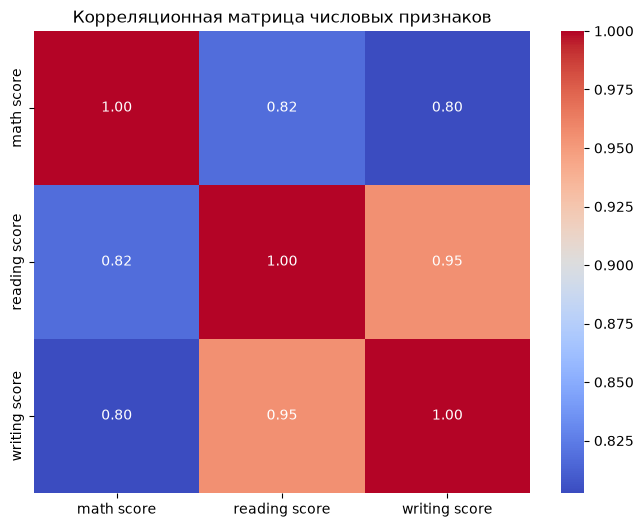

In [11]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Корреляционная матрица числовых признаков")
plt.show()

In [12]:
X_reduced = df[["reading score"]]
y = df["math score"]

In [13]:
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=42
)

In [14]:
model_reduced = LinearRegression()

model_reduced.fit(X_train_red, y_train_red)

y_pred_reduced = model_reduced.predict(X_test_red)

In [15]:
mae_reduced = mean_absolute_error(y_test_red, y_pred_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_test_red, y_pred_reduced))
r2_reduced = r2_score(y_test_red, y_pred_reduced)

print("Сокращённая модель")
print("MAE:", mae_reduced)
print("RMSE:", rmse_reduced)
print("R²:", r2_reduced)

Сокращённая модель
MAE: 7.280881770618455
RMSE: 8.818136981676858
R²: 0.6804469009921283


In [16]:
results = pd.DataFrame({
    "Модель": [
        "Базовая",
        "Сокращённая"
    ],
    "Признаки": [
        "reading score + writing score",
        "reading score"
    ],
    "MAE": [
        mae_base,
        mae_reduced
    ],
    "RMSE": [
        rmse_base,
        rmse_reduced
    ],
    "R²": [
        r2_base,
        r2_reduced
    ]
})

results

,Модель,Признаки,MAE,RMSE,R²
0,Базовая,reading score + writing score,7.351309,8.788798,0.682570
1,Сокращённая,reading score,7.280882,8.818137,0.680447


In [17]:
residuals = y_test - y_pred_reduced

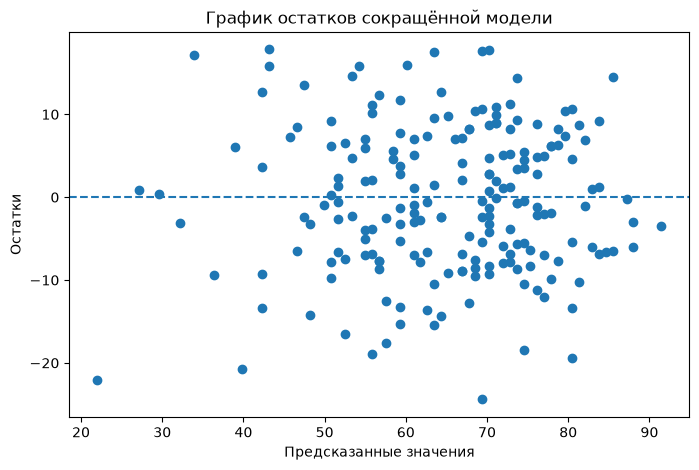

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_reduced, residuals)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков сокращённой модели")

plt.show()